# 07 · Elasticidade da demanda por aluguel — onde o sobrepreço espanta o inquilino?

**Entrada:** `data/interim/aluguel_sp_clean.parquet` (coleta de 29/07, saída do notebook 01) e a coleta de 14/10
(`data/raw/quintoandar/quintoandar_sp_20261014_2209.parquet`, feita pelo retreino automático).

**Hipóteses do autor:**
- **E1** — Regiões mais ricas são **inelásticas** ao preço; regiões periféricas são **elásticas**.
- **E2** — Apartamentos são mais inelásticos que casas.

### Como medir elasticidade só com anúncios

Elasticidade-preço da demanda é quanto a quantidade demandada cai quando o preço sobe. Anúncios mostram o preço
pedido, não quem alugou — mas temos **duas fotografias do mercado com 77 dias de intervalo**. Um anúncio de julho que
**sumiu** em outubro foi, na maioria dos casos, alugado. Daí o desenho:

1. **Preço justo:** modelo hedônico OLS de `log(aluguel)` com planta, tipo, mobília e **efeito fixo de região**.
   O resíduo é o **prêmio**: quanto o anúncio pede acima (ou abaixo) de imóveis parecidos *na mesma região*.
2. **Demanda:** probabilidade de sair do mercado em 77 dias em função do prêmio (logit).
3. **Elasticidade:** quanto essa probabilidade cai a cada +10% de sobrepreço. Onde a queda é forte, o inquilino troca
   de imóvel ao ver preço alto (**elástica**); onde é fraca, aluga mesmo assim (**inelástica**).

Também medimos `ε = (dP/P) / (dPreço/Preço)`, a elasticidade da chance de alugar em relação ao preço.

### Limitações (lidas antes dos resultados)

- **Sair ≠ alugar com certeza:** o anunciante também pode desistir. O viés afeta todos os grupos, e a comparação é
  relativa (qual grupo é *mais* elástico), não um valor absoluto.
- **O prêmio absorve qualidade não observada** (reforma, vista, fotos). Um imóvel "caro" pode ser só melhor — isso
  **atenua** a elasticidade medida; o efeito real tende a ser maior.
- **Uma janela de 77 dias** (agosto a outubro). Sazonalidade não é controlada.

## 1. Setup e carga

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

pd.options.display.float_format = "{:,.3f}".format
pd.set_option("display.max_columns", 60)
sns.set_theme(style="whitegrid", context="notebook")

COR = "#2a6f97"
CINZA = "#c0c7cf"
TIPOS = ["Apartamento", "Casa", "StudioOuKitchenette", "CasaCondominio"]
PALETA = dict(zip(TIPOS, ["#2a6f97", "#e07a1f", "#3a9d5d", "#8e5ba8"]))
GRUPOS = ["periferia", "intermediária", "nobre"]
PALETA_GRUPO = dict(zip(GRUPOS, ["#e07a1f", "#9aa5b1", "#2a6f97"]))
ALFA = 0.05


def achar_raiz(marcador: str = ".git") -> Path:
    p = Path.cwd().resolve()
    for candidato in [p, *p.parents]:
        if (candidato / marcador).exists():
            return candidato
    raise FileNotFoundError(f"Raiz do projeto ({marcador}) não encontrada a partir de {p}")


ROOT = achar_raiz()
df = pd.read_parquet(ROOT / "data/interim/aluguel_sp_clean.parquet")
outubro = pd.read_parquet(ROOT / "data/raw/quintoandar/quintoandar_sp_20261014_2209.parquet",
                          columns=["id", "rent"]).rename(columns={"rent": "rent_out"})
print(f"julho (limpo): {df.shape} | outubro (bruto): {outubro.shape}")

julho (limpo): (22213, 96) | outubro (bruto): (30236, 2)


In [2]:
# Desfechos de demanda
df = df.merge(outubro, on="id", how="left")
df["saiu"] = df["rent_out"].isna().astype(int)                      # sumiu entre 29/07 e 14/10
df["variacao"] = df["rent_out"] / df["rent"] - 1                     # só para quem ficou
df["baixou"] = np.where(df["saiu"] == 0, (df["variacao"] < -0.001).astype(float), np.nan)

# Variáveis do modelo hedônico (mesmas escolhas do notebook 02)
df["log_area"] = np.log(df["area"])
df["mobiliado"] = df["isFurnished"].fillna(False).astype(int)
df[["suites", "parkingSpaces"]] = df[["suites", "parkingSpaces"]].fillna(0)

# Só regiões com n >= 30 (efeito fixo estável)
df = df[df.groupby("regionName")["id"].transform("size") >= 30].copy()
print(f"anúncios: {len(df):,} em {df['regionName'].nunique()} regiões")
print(f"saíram do mercado: {df['saiu'].mean():.1%} | dos que ficaram, baixaram o preço: {df['baixou'].mean():.1%}")

anúncios: 20,323 em 133 regiões
saíram do mercado: 62.1% | dos que ficaram, baixaram o preço: 48.1%


## 2. Grupos de regiões

Regiões ordenadas pelo **R$/m² mediano** e divididas em tercis: **periferia** (mais barato), **intermediária** e
**nobre**. Na seção 7 a análise é refeita por região, sem cortes arbitrários.

In [3]:
m2_regiao = df.groupby("regionName")["rent_m2"].median()
corte = m2_regiao.quantile([1 / 3, 2 / 3]).to_numpy()
grupo_regiao = pd.cut(m2_regiao, [-np.inf, *corte, np.inf], labels=GRUPOS)
df["grupo"] = pd.Categorical(df["regionName"].map(grupo_regiao), categories=GRUPOS)

panorama = (df.groupby("grupo", observed=True)
              .agg(regioes=("regionName", "nunique"), anuncios=("id", "size"),
                   rs_m2=("rent_m2", "median"), aluguel=("rent", "median"),
                   saiu=("saiu", "mean"), baixou=("baixou", "mean")))
panorama

,regioes,anuncios,rs_m2,aluguel,saiu,baixou
grupo,,,,,,
periferia,45,4250,32.500,"1,810.000",0.643,0.460
intermediária,44,5699,45.429,"2,600.000",0.631,0.462
nobre,44,10374,71.429,"3,200.000",0.608,0.499


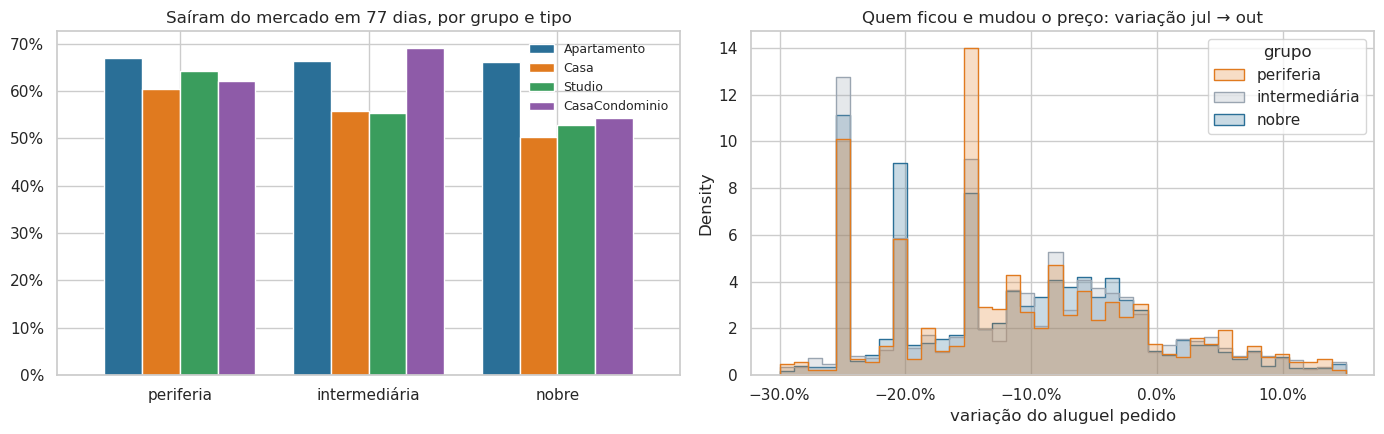

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
tx = df.groupby(["grupo", "type"], observed=True)["saiu"].mean().unstack()[TIPOS]
tx.plot.bar(ax=axes[0], color=[PALETA[t] for t in TIPOS], width=0.8, edgecolor="white")
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1))
axes[0].set_title("Saíram do mercado em 77 dias, por grupo e tipo")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=0)
axes[0].legend([t.replace("OuKitchenette", "") for t in TIPOS], frameon=False, fontsize=9)

ficaram = df[df["saiu"] == 0]
sns.histplot(data=ficaram[ficaram["variacao"].abs() > 0.001], x="variacao", hue="grupo", hue_order=GRUPOS,
             palette=PALETA_GRUPO, element="step", stat="density", common_norm=False, bins=40,
             binrange=(-0.3, 0.15), ax=axes[1])
axes[1].xaxis.set_major_formatter(mtick.PercentFormatter(1))
axes[1].set_title("Quem ficou e mudou o preço: variação jul → out")
axes[1].set_xlabel("variação do aluguel pedido")
plt.tight_layout()
plt.show()

## 3. Preço justo e prêmio

`log(aluguel) ~ log(área) + quartos + banheiros + suítes + vagas + tipo + mobiliado + região`.
O resíduo (`prêmio`) é o sobrepreço em log: 0,10 ≈ 10% acima de imóveis parecidos na mesma região.

R² do modelo hedônico: 0.815
prêmio: desvio 0.292 | P10 -0.34 | P90 +0.36


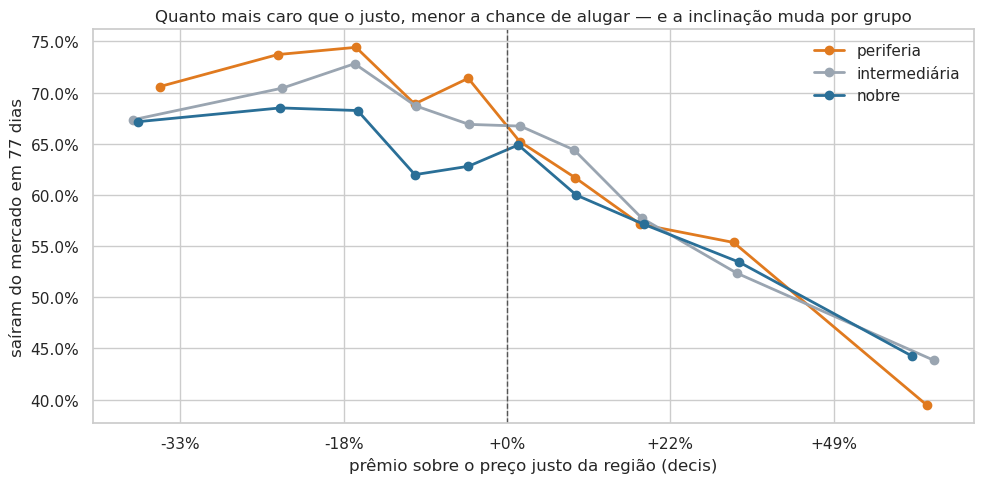

In [5]:
hedonico = smf.ols(
    "log_rent ~ log_area + bedrooms + bathrooms + suites + parkingSpaces + C(type) + mobiliado + C(regionName)",
    data=df,
).fit()
df["premio"] = hedonico.resid
print(f"R² do modelo hedônico: {hedonico.rsquared:.3f}")
print(f"prêmio: desvio {df['premio'].std():.3f} | P10 {df['premio'].quantile(.1):+.2f} | P90 {df['premio'].quantile(.9):+.2f}")

# Prova visual: probabilidade de sair por decil de prêmio, por grupo
df["decil_premio"] = pd.qcut(df["premio"], 10, labels=False) + 1
curva = df.groupby(["grupo", "decil_premio"], observed=True).agg(saiu=("saiu", "mean"), premio=("premio", "median")).reset_index()

fig, ax = plt.subplots(figsize=(10, 5))
for g in GRUPOS:
    c = curva[curva["grupo"] == g]
    ax.plot(c["premio"], c["saiu"], marker="o", lw=2, color=PALETA_GRUPO[g], label=g)
ax.axvline(0, color="#555", ls="--", lw=1)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{np.exp(v) - 1:+.0%}"))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_xlabel("prêmio sobre o preço justo da região (decis)")
ax.set_ylabel("saíram do mercado em 77 dias")
ax.set_title("Quanto mais caro que o justo, menor a chance de alugar — e a inclinação muda por grupo")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## 4. E1 — A periferia é mais elástica que as regiões nobres?

Logit `saiu ~ prêmio × grupo + log(área) + tipo`. O **efeito marginal** do prêmio em cada grupo vira
"pontos percentuais de chance de alugar perdidos a cada +10% de sobrepreço", e `ε` divide isso pela taxa de saída
do grupo.

- H0: a inclinação do prêmio é igual nos três grupos (interações = 0)
- H1: a periferia tem inclinação mais negativa (mais elástica)

In [6]:
def elasticidade(dados, formula="saiu ~ premio + log_area + C(type)"):
    # Efeito marginal médio do prêmio (em log) -> p.p. por +10% de preço e elasticidade ε
    m = smf.logit(formula, data=dados).fit(disp=0)
    me = m.get_margeff().summary_frame().loc["premio"]
    passo = np.log(1.10)
    taxa = dados["saiu"].mean()
    return {
        "n": len(dados), "saída": taxa, "coef": m.params["premio"],
        "pp_por_10%": me["dy/dx"] * passo, "IC95 inf": me["Conf. Int. Low"] * passo, "IC95 sup": me["Cont. Int. Hi."] * passo,
        "ε": me["dy/dx"] / taxa,
    }


por_grupo = pd.DataFrame({g: elasticidade(d) for g, d in df.groupby("grupo", observed=True)}).T
interacao = smf.logit("saiu ~ premio * C(grupo) + log_area + C(type)", data=df).fit(disp=0)
p_inter = interacao.pvalues.filter(like="premio:")
print(por_grupo.round(3).to_string())
print("\nInterações (referência: periferia):")
print(pd.DataFrame({"coef": interacao.params.filter(like="premio:"), "p": p_inter}).round(4).to_string())

                       n  saída   coef  pp_por_10%  IC95 inf  IC95 sup      ε
periferia      4,250.000  0.643 -1.493      -0.031    -0.035    -0.026 -0.499
intermediária  5,699.000  0.631 -1.022      -0.022    -0.025    -0.018 -0.358
nobre         10,374.000  0.608 -1.000      -0.022    -0.025    -0.019 -0.377

Interações (referência: periferia):
                                  coef     p
premio:C(grupo)[T.intermediária] 0.469 0.002
premio:C(grupo)[T.nobre]         0.500 0.000


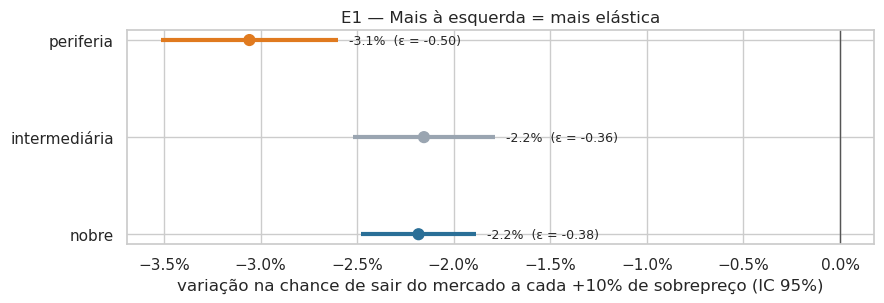

In [7]:
def grafico_efeitos(tabela, cores, titulo):
    fig, ax = plt.subplots(figsize=(9, 0.6 * len(tabela) + 1.4))
    y = np.arange(len(tabela))[::-1]
    ax.hlines(y, tabela["IC95 inf"], tabela["IC95 sup"], color=cores, lw=3)
    ax.scatter(tabela["pp_por_10%"], y, color=cores, s=60, zorder=3)
    for yi, (_, r) in zip(y, tabela.iterrows()):
        ax.annotate(f"{r['pp_por_10%']:+.1%}  (ε = {r['ε']:.2f})", (r["IC95 sup"], yi), xytext=(8, -3),
                    textcoords="offset points", fontsize=9)
    ax.axvline(0, color="#555", lw=1)
    ax.set_yticks(y, tabela.index)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=1))
    ax.set_xlabel("variação na chance de sair do mercado a cada +10% de sobrepreço (IC 95%)")
    ax.set_title(titulo)
    plt.tight_layout()
    plt.show()


grafico_efeitos(por_grupo, [PALETA_GRUPO[g] for g in por_grupo.index],
                "E1 — Mais à esquerda = mais elástica")

## 5. E2 — Apartamentos são mais inelásticos que casas?

Mesmo logit, separando por tipo e controlando o grupo de região (o efeito fixo de região não cabe: há poucas casas
por região).

                             n  saída   coef  pp_por_10%  IC95 inf  IC95 sup      ε
Apartamento         12,591.000  0.663 -0.936      -0.020    -0.022    -0.017 -0.309
Casa                 4,174.000  0.560 -1.251      -0.026    -0.030    -0.022 -0.496
StudioOuKitchenette  3,263.000  0.537 -1.443      -0.033    -0.039    -0.027 -0.646
CasaCondominio         295.000  0.637 -2.016      -0.040    -0.054    -0.025 -0.655

Interações (referência: Apartamento):
                                                                  coef     p
premio:C(type, Treatment('Apartamento'))[T.Casa]                -0.280 0.020
premio:C(type, Treatment('Apartamento'))[T.CasaCondominio]      -1.064 0.014
premio:C(type, Treatment('Apartamento'))[T.StudioOuKitchenette] -0.523 0.001


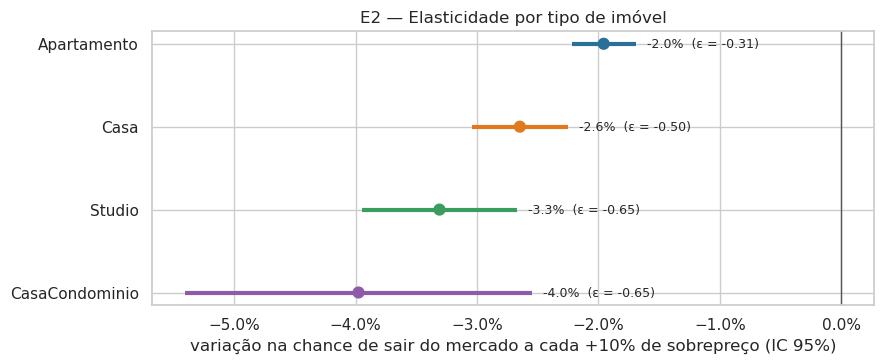

In [8]:
por_tipo = pd.DataFrame({
    t: elasticidade(d, "saiu ~ premio + log_area + C(grupo)")
    for t, d in df.groupby("type") if t in TIPOS
}).T.loc[TIPOS]
inter_tipo = smf.logit("saiu ~ premio * C(type, Treatment('Apartamento')) + log_area + C(grupo)", data=df).fit(disp=0)
print(por_tipo.round(3).to_string())
print("\nInterações (referência: Apartamento):")
print(pd.DataFrame({"coef": inter_tipo.params.filter(like="premio:"),
                    "p": inter_tipo.pvalues.filter(like="premio:")}).round(4).to_string())
grafico_efeitos(por_tipo.rename(index=lambda t: t.replace("OuKitchenette", "")), [PALETA[t] for t in TIPOS],
                "E2 — Elasticidade por tipo de imóvel")

In [9]:
# Cruzamento: apartamento nobre × casa periférica (a combinação da hipótese do autor)
cruz = pd.DataFrame({
    f"{t.replace('OuKitchenette', '')} · {g}": elasticidade(d)
    for (t, g), d in df[df["type"].isin(["Apartamento", "Casa"])].groupby(["type", "grupo"], observed=True)
}).T
cruz[["n", "saída", "pp_por_10%", "IC95 inf", "IC95 sup", "ε"]].round(3)

,n,saída,pp_por_10%,IC95 inf,IC95 sup,ε
Apartamento · periferia,"2,411.000",0.669,-0.029,-0.036,-0.023,-0.462
Apartamento · intermediária,"3,781.000",0.663,-0.019,-0.024,-0.014,-0.298
Apartamento · nobre,"6,399.000",0.661,-0.017,-0.021,-0.014,-0.278
Casa · periferia,"1,602.000",0.604,-0.030,-0.037,-0.023,-0.522
Casa · intermediária,"1,324.000",0.558,-0.023,-0.030,-0.017,-0.441
Casa · nobre,"1,248.000",0.504,-0.026,-0.033,-0.019,-0.549


## 6. Sinal complementar — quem estava caro e ficou, baixou o preço?

Se a demanda reage ao preço, anúncios acima do justo que **não** alugaram deveriam ter **baixado** o preço com mais
frequência. Logit `baixou ~ prêmio × grupo` entre os que continuaram anunciados.

In [10]:
ficaram = df[df["saiu"] == 0].copy()
baixa = {}
for g, d in ficaram.groupby("grupo", observed=True):
    m = smf.logit("baixou ~ premio + log_area + C(type)", data=d).fit(disp=0)
    me = m.get_margeff().summary_frame().loc["premio"]
    baixa[g] = {"n": len(d), "baixaram": d["baixou"].mean(), "pp_por_10%": me["dy/dx"] * np.log(1.1),
                "p": me["Pr(>|z|)"]}
pd.DataFrame(baixa).T.round(4)

,n,baixaram,pp_por_10%,p
periferia,"1,518.000",0.461,0.013,0.001
intermediária,"2,105.000",0.462,0.015,0.000
nobre,"4,070.000",0.499,0.010,0.000


## 7. Elasticidade por região × riqueza da região

Sem cortes em tercis: uma elasticidade por região (regiões com ≥ 250 anúncios) contra o R$/m² mediano da região.
Se E1 vale, a correlação é **positiva** (regiões caras → efeito menos negativo → mais inelásticas).

/home/felipe/anaconda3/envs/regression/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/felipe/anaconda3/envs/regression/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/felipe/anaconda3/envs/regression/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/felipe/anaconda3/envs/regression/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


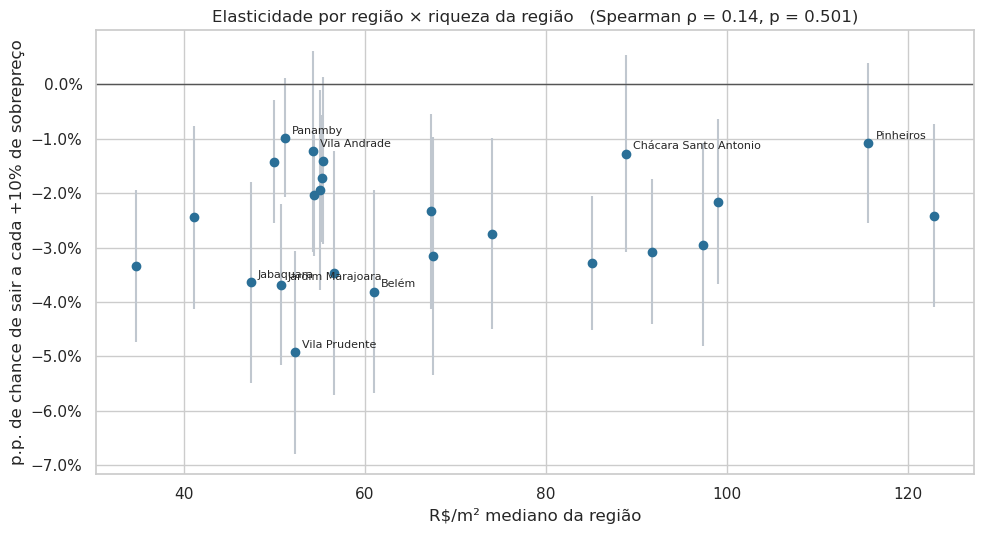

24 regiões. Mais elásticas:
                    n  rs_m2  pp_por_10%      ε
região                                         
Vila Prudente     270 52.265      -0.049 -0.856
Belém             324 60.992      -0.038 -0.647
Jardim Marajoara  318 50.705      -0.037 -0.620
Jabaquara         259 47.429      -0.036 -0.582
Saúde             256 56.598      -0.035 -0.578

Mais inelásticas:
                         n   rs_m2  pp_por_10%      ε
região                                               
Água Fria              405  55.357      -0.014 -0.247
Chácara Santo Antonio  335  88.889      -0.013 -0.244
Vila Andrade           317  54.286      -0.012 -0.186
Pinheiros              607 115.625      -0.011 -0.188
Panamby                357  51.163      -0.010 -0.163


In [11]:
regioes = []
for r, d in df.groupby("regionName"):
    if len(d) < 250:
        continue
    e = elasticidade(d)
    regioes.append({"região": r, "rs_m2": d["rent_m2"].median(), **e})
regioes = pd.DataFrame(regioes).set_index("região").sort_values("pp_por_10%")
rho, p_rho = stats.spearmanr(regioes["rs_m2"], regioes["pp_por_10%"])

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.errorbar(regioes["rs_m2"], regioes["pp_por_10%"],
            yerr=[regioes["pp_por_10%"] - regioes["IC95 inf"], regioes["IC95 sup"] - regioes["pp_por_10%"]],
            fmt="o", color=COR, ecolor=CINZA, elinewidth=1.5, capsize=0, ms=6)
for nome, r in pd.concat([regioes.head(4), regioes.tail(4)]).iterrows():
    ax.annotate(nome, (r["rs_m2"], r["pp_por_10%"]), xytext=(5, 3), textcoords="offset points", fontsize=8)
ax.axhline(0, color="#555", lw=1)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=1))
ax.set_xlabel("R$/m² mediano da região")
ax.set_ylabel("p.p. de chance de sair a cada +10% de sobrepreço")
ax.set_title(f"Elasticidade por região × riqueza da região   (Spearman ρ = {rho:.2f}, p = {p_rho:.3f})")
plt.tight_layout()
plt.show()

print(f"{len(regioes)} regiões. Mais elásticas:")
print(regioes.head(5)[["n", "rs_m2", "pp_por_10%", "ε"]].round(3).to_string())
print("\nMais inelásticas:")
print(regioes.tail(5)[["n", "rs_m2", "pp_por_10%", "ε"]].round(3).to_string())

## 8. Robustez

O resultado de E1 não pode depender de uma escolha. Refazemos com:
- **grupos por distância ao centro** em vez de R$/m² (periferia = mais longe);
- **sem prêmios extremos** (|prêmio| > 0,6, possíveis erros de cadastro);
- **só apartamentos**, para separar o efeito da região do efeito do tipo.

In [12]:
df["grupo_dist"] = pd.qcut(df["dist_centro_km"], 3, labels=["perto do centro", "meio", "longe (periferia)"])
robustez = {
    "R$/m² (principal)": por_grupo["pp_por_10%"],
    "distância ao centro": pd.Series({g: elasticidade(d)["pp_por_10%"]
                                      for g, d in df.groupby("grupo_dist", observed=True)})
                             .rename({"longe (periferia)": "periferia", "meio": "intermediária",
                                      "perto do centro": "nobre"}),
    "sem prêmios extremos": pd.Series({g: elasticidade(d)["pp_por_10%"]
                                       for g, d in df[df["premio"].abs() <= 0.6].groupby("grupo", observed=True)}),
    "só apartamentos": pd.Series({g: elasticidade(d, "saiu ~ premio + log_area")["pp_por_10%"]
                                  for g, d in df[df["type"] == "Apartamento"].groupby("grupo", observed=True)}),
}
robustez = pd.DataFrame(robustez).loc[GRUPOS]
robustez.style.format("{:+.2%}")

,R$/m² (principal),distância ao centro,sem prêmios extremos,só apartamentos
periferia,-3.06%,-2.42%,-3.05%,-2.95%
intermediária,-2.15%,-2.53%,-2.76%,-1.89%
nobre,-2.18%,-2.02%,-2.44%,-1.75%


## 9. Conclusões

> Números da execução de referência (coletas de 29/07 e 14/10); confira contra a sua execução.

### O que os dados dizem

| Hipótese | Resultado | Evidência |
|---|---|---|
| **E1** — periferia elástica, regiões ricas inelásticas | **Confirmada em parte** | O tercil mais barato de regiões é o mais elástico: −3,1 p.p. de chance de alugar a cada +10% de sobrepreço (ε = −0,50), contra −2,2 p.p. nas intermediárias e nas nobres (ε ≈ −0,37); interações significativas (p ≤ 0,002). Mas **não há gradiente acima da periferia**, e por região, em escala contínua, a correlação com o R$/m² é fraca (ρ = 0,14, p = 0,50) |
| **E2** — apartamento mais inelástico que casa | **Confirmada** | Apartamento ε = −0,31; casa −0,50; studio −0,65 (interações p ≤ 0,02). O mais inelástico de todos é o **apartamento em região nobre** (−1,7 p.p.); o apartamento na periferia reage quase como uma casa (−2,9 p.p.) |
| Sinal complementar | Coerente | Quem estava caro e não alugou baixou o preço com mais frequência em todos os grupos (+1,0 a +1,5 p.p. a cada +10% de sobrepreço) — menos nas nobres |

### Leitura

1. **A elasticidade tem um degrau, não uma rampa.** O inquilino da periferia (aluguel mediano de R$ 1.810) troca de
   imóvel ao ver sobrepreço; acima desse patamar, a reação é parecida. O orçamento apertado — não a "riqueza" da
   região em si — parece ser o que torna a demanda sensível.
2. **O tipo pesa mais que a região.** A combinação da hipótese — apartamento em região nobre — é de fato a mais
   inelástica; casas reagem igual em qualquer região.
3. **Em sentido estrito, tudo é inelástico** (|ε| < 1): um sobrepreço de 10% reduz a chance de alugar em 77 dias em
   2 a 4 p.p., partindo de ~62%. Como o prêmio absorve qualidade não observada, os efeitos reais tendem a ser maiores.

### Robustez

- Sem prêmios extremos e só com apartamentos, a periferia continua a mais elástica.
- Com grupos por **distância ao centro**, a diferença quase some (−2,4 / −2,5 / −2,0 p.p.): "periferia" como preço
  baixo do m² e como distância não são a mesma coisa (ver H9 do notebook 02, pico de preço a ~4 km da Sé).

### Implicações para o projeto

- **Produto:** o selo "acima do mercado" do estimador importa mais para studios, casas e anúncios em regiões de
  R$/m² baixo — é onde o sobrepreço mais custa em tempo de vacância.
- **Próximo passo de dados:** com coletas periódicas do retreino automático, dá para medir o **tempo até sair** (não só
  sair/ficar em 77 dias) com um modelo de sobrevivência, e acompanhar a elasticidade ao longo do ano.